In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import yfinance as yf

In [2]:
acoes = [ "BBAS3.SA",
    "ITUB4.SA",
    "SANB4.SA",
    "BBDC4.SA",
    "BMGB4.SA",
    "BRSR6.SA",
    "BOVA11.SA"]
acoes_df = {}
for acao in acoes:
    df = yf.download(acao, start="2020-01-01", end="2027-01-01", auto_adjust=True)
    df.columns = df.columns.droplevel(1) if isinstance(df.columns, pd.MultiIndex) else df.columns
    acoes_df[acao] = df["Close"]

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [3]:
acoes_combined = pd.concat(acoes_df, axis=1)

# Remove MultiIndex só se existir
if isinstance(acoes_combined.columns, pd.MultiIndex):
    acoes_combined.columns = acoes_combined.columns.droplevel(0)

acoes_combined = acoes_combined.rename(columns={
    "BBAS3.SA": "BBRASIL",
    "ITUB4.SA": "ITAU",
    "SANB4.SA": "SANTANDER",
    "BBDC4.SA": "BRADESCO",
    "BMGB4.SA": "BMG",
    "BRSR6.SA": "BANRISUL",
    "BOVA11.SA": "BOVA11"
})

print(acoes_combined.head())
print(acoes_combined.tail())
acoes_combined.describe()

              BBRASIL       ITAU  SANTANDER   BRADESCO       BMG   BANRISUL  \
Date                                                                          
2020-01-02  16.931356  22.936810  14.608781  18.192394  5.041269  12.942718   
2020-01-03  16.903036  22.695555  14.993228  18.201591  4.999213  12.855424   
2020-01-06  16.679594  22.357798  14.187619  17.876471  4.883563  12.832145   
2020-01-07  16.553711  21.839123  13.983168  17.565918  4.888821  12.890341   
2020-01-08  16.402645  21.483276  13.791107  17.294170  4.862536  12.610998   

                BOVA11  
Date                    
2020-01-02  114.239998  
2020-01-03  113.800003  
2020-01-06  112.589996  
2020-01-07  112.239998  
2020-01-08  111.949997  
              BBRASIL       ITAU  SANTANDER   BRADESCO   BMG  BANRISUL  \
Date                                                                     
2026-10-23  24.719999  48.299999      13.78  20.370001  7.21     18.16   
2026-10-26  17.469999  41.700001      13.15  15.9

,BBRASIL,ITAU,SANTANDER,BRADESCO,BMG,BANRISUL,BOVA11
count,1701.000000,1701.000000,1701.000000,1701.000000,1701.000000,1701.000000,1700.000000
mean,17.488954,23.746845,12.655969,13.307127,2.828071,9.556412,121.674549
std,5.689959,8.975010,1.677267,2.643867,1.201929,2.711805,25.670030
min,7.062580,12.765544,7.434560,8.601515,1.279367,6.046511,61.139999
25%,11.502273,17.180603,11.788450,11.150435,1.798476,7.601405,105.925001
50%,18.075335,19.772736,12.736300,12.805286,2.659939,8.812904,115.605000
75%,22.818197,27.425262,13.650843,14.705662,3.242903,10.528664,128.764996
max,28.405668,50.470001,18.018944,22.420448,7.230000,18.870001,205.550003


In [4]:
acoes = ["BBAS3.SA", "ITUB4.SA", "SANB4.SA", "BBDC4.SA", "BMGB4.SA", "BRSR6.SA", "BOVA11.SA"]

In [5]:
acoes_combined.isnull().sum()

BBRASIL      0
ITAU         0
SANTANDER    0
BRADESCO     0
BMG          0
BANRISUL     0
BOVA11       1
dtype: int64

In [6]:
acoes_combined.columns

Index(['BBRASIL', 'ITAU', 'SANTANDER', 'BRADESCO', 'BMG', 'BANRISUL',
       'BOVA11'],
      dtype='object')

In [7]:
acoes_combined.describe()

,BBRASIL,ITAU,SANTANDER,BRADESCO,BMG,BANRISUL,BOVA11
count,1701.000000,1701.000000,1701.000000,1701.000000,1701.000000,1701.000000,1700.000000
mean,17.488954,23.746845,12.655969,13.307127,2.828071,9.556412,121.674549
std,5.689959,8.975010,1.677267,2.643867,1.201929,2.711805,25.670030
min,7.062580,12.765544,7.434560,8.601515,1.279367,6.046511,61.139999
25%,11.502273,17.180603,11.788450,11.150435,1.798476,7.601405,105.925001
50%,18.075335,19.772736,12.736300,12.805286,2.659939,8.812904,115.605000
75%,22.818197,27.425262,13.650843,14.705662,3.242903,10.528664,128.764996
max,28.405668,50.470001,18.018944,22.420448,7.230000,18.870001,205.550003


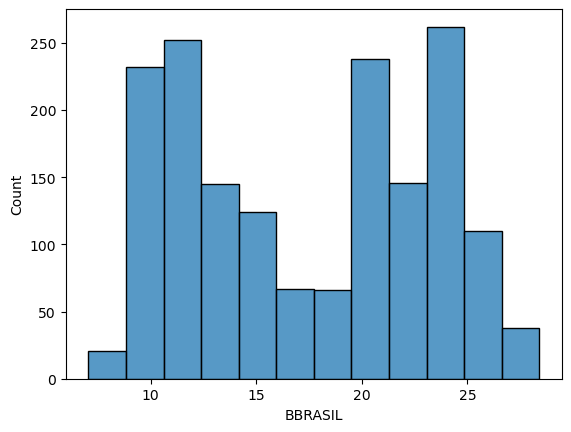

In [8]:
sns.histplot(acoes_combined["BBRASIL"]);

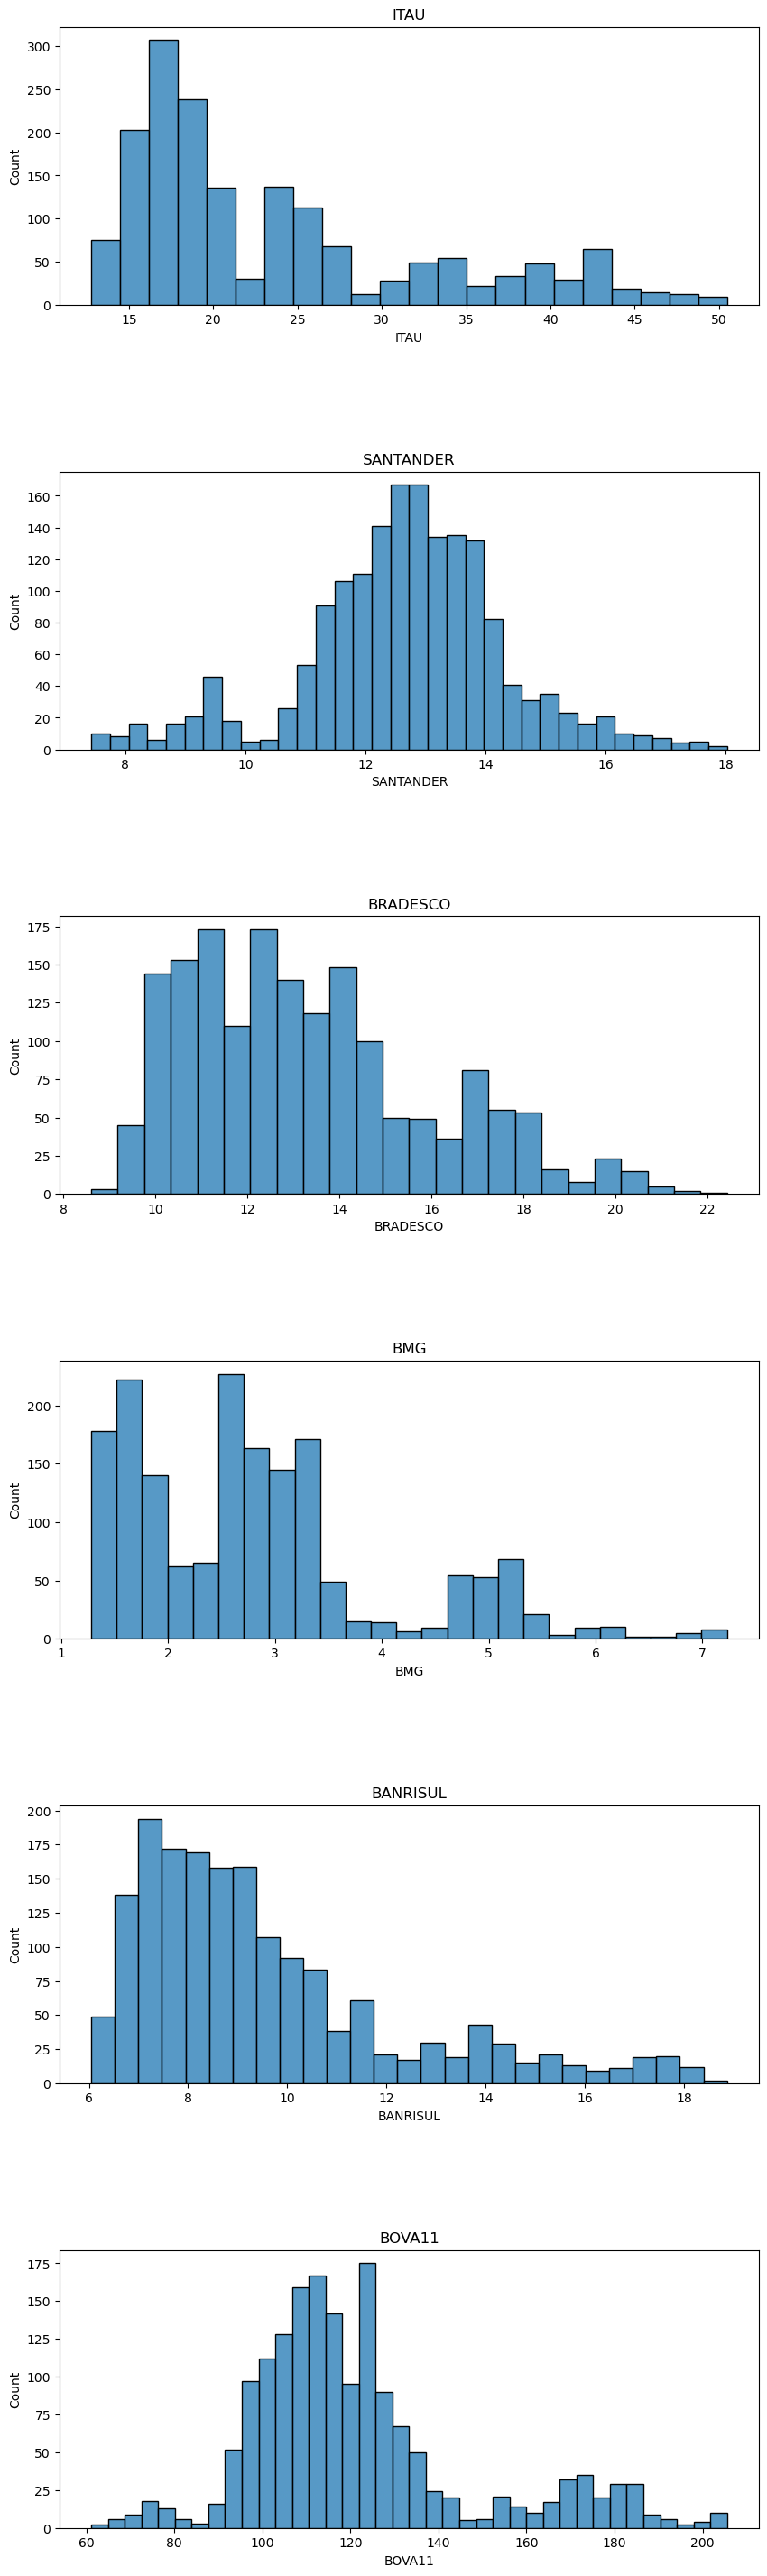

In [9]:

plt.figure(figsize=(10,36))

for i in np.arange(1, len(acoes_combined.columns)):
    plt.subplot(6,1, i)
    sns.histplot(acoes_combined[acoes_combined.columns[i]])
    plt.title(acoes_combined.columns[i])

plt.subplots_adjust(hspace=0.6)
plt.show()


In [10]:
acoes_combined

,BBRASIL,ITAU,SANTANDER,BRADESCO,BMG,BANRISUL,BOVA11
Date,,,,,,,
2020-01-02,16.931356,22.936810,14.608781,18.192394,5.041269,12.942718,114.239998
2020-01-03,16.903036,22.695555,14.993228,18.201591,4.999213,12.855424,113.800003
2020-01-06,16.679594,22.357798,14.187619,17.876471,4.883563,12.832145,112.589996
2020-01-07,16.553711,21.839123,13.983168,17.565918,4.888821,12.890341,112.239998
2020-01-08,16.402645,21.483276,13.791107,17.294170,4.862536,12.610998,111.949997
...,...,...,...,...,...,...,...
2026-10-23,24.719999,48.299999,13.780000,20.370001,7.210000,18.160000,201.690002
2026-10-26,17.469999,41.700001,13.150000,15.950000,6.160000,14.530000,172.419998
2026-10-27,17.379999,41.189999,13.000000,15.730000,5.710000,13.610000,173.000000


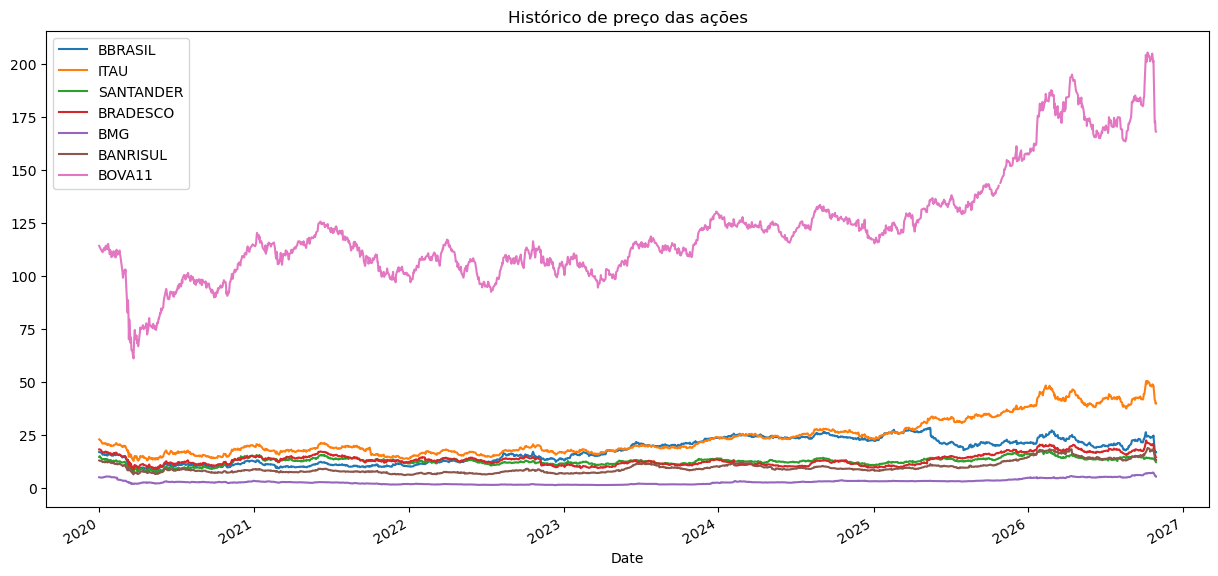

In [11]:
acoes_combined.plot(figsize = (15,7), title = "Histórico de preço das ações");

In [12]:
acoes_combined_normalizado = acoes_combined.copy()
for i in acoes_combined_normalizado.columns[0:]:
    acoes_combined_normalizado[i] = acoes_combined_normalizado[i] / acoes_combined_normalizado[i][0]

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\361204779.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  acoes_combined_normalizado[i] = acoes_combined_normalizado[i] / acoes_combined_normalizado[i][0]


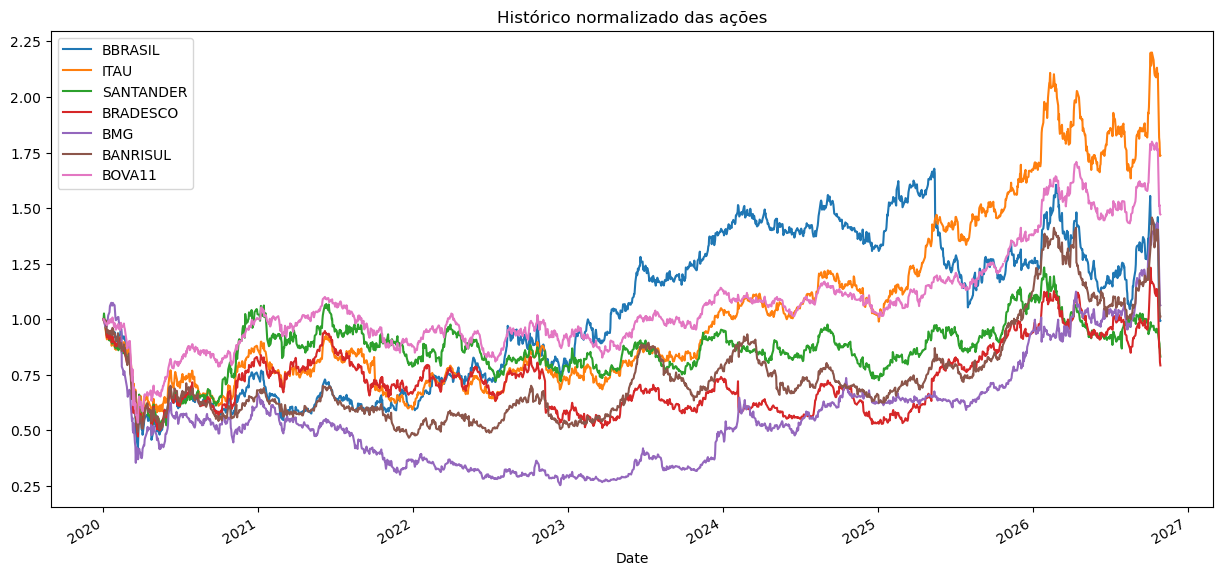

In [13]:
acoes_combined_normalizado.plot(figsize = (15,7), title = "Histórico normalizado das ações");

In [14]:
figura = px.line(title = "Histórico de preço das açoes")
for i in acoes_combined_normalizado.columns[0:]:
    figura.add_scatter(x=acoes_combined_normalizado.index, y=acoes_combined_normalizado[i], name=i)
figura.show()

In [15]:
len(acoes_combined)

1701

In [16]:
acoes_combined["BBRASIL"][0], acoes_combined["BBRASIL"][-1]

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\2522176333.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



(np.float64(16.93135643005371), np.float64(16.81999969482422))

In [17]:
((acoes_combined["BBRASIL"][len(acoes_combined) - 1] - acoes_combined["BBRASIL"][0]) / acoes_combined["BBRASIL"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\669563851.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(-0.6576952985989376)

In [18]:
((acoes_combined["BMG"][len(acoes_combined) - 1] - acoes_combined["BMG"][0]) / acoes_combined["BMG"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\3692447727.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(6.322442206795547)

In [19]:
((acoes_combined["ITAU"][len(acoes_combined) - 1] - acoes_combined["ITAU"][0]) / acoes_combined["ITAU"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\904235323.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(73.69460248369006)

In [20]:
((acoes_combined["BANRISUL"][len(acoes_combined) - 1] - acoes_combined["BANRISUL"][0]) / acoes_combined["BANRISUL"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\4097820066.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(1.2924805305972704)

In [21]:
((acoes_combined["BRADESCO"][len(acoes_combined) - 1] - acoes_combined["BRADESCO"][0]) / acoes_combined["BRADESCO"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\2043861980.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(-20.736106128147313)

In [22]:
((acoes_combined["SANTANDER"][len(acoes_combined) - 1] - acoes_combined["SANTANDER"][0]) / acoes_combined["SANTANDER"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\1382640219.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(-16.762391309754786)

In [23]:
((acoes_combined["BOVA11"][len(acoes_combined) - 1] - acoes_combined["BOVA11"][0]) / acoes_combined["BOVA11"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\218357033.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(47.20763420311594)

In [24]:
(acoes_combined["SANTANDER"][len(acoes_combined) - 1] / acoes_combined["SANTANDER"][0] - 1) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\263952419.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(-16.762391309754786)

In [25]:
acoes_combined["BBRASIL"].shift(1)

Date
2020-01-02          NaN
2020-01-03    16.931356
2020-01-06    16.903036
2020-01-07    16.679594
2020-01-08    16.553711
                ...    
2026-10-23    23.920000
2026-10-26    24.719999
2026-10-27    17.469999
2026-10-28    17.379999
2026-10-29    16.790001
Name: BBRASIL, Length: 1701, dtype: float64

In [26]:
acoes_combined["RS BBRASIL"] =  (acoes_combined["BBRASIL"] / acoes_combined["BBRASIL"].shift(1)) - 1

In [27]:
acoes_combined

,BBRASIL,ITAU,SANTANDER,BRADESCO,BMG,BANRISUL,BOVA11,RS BBRASIL
Date,,,,,,,,
2020-01-02,16.931356,22.936810,14.608781,18.192394,5.041269,12.942718,114.239998,NaN
2020-01-03,16.903036,22.695555,14.993228,18.201591,4.999213,12.855424,113.800003,-0.001673
2020-01-06,16.679594,22.357798,14.187619,17.876471,4.883563,12.832145,112.589996,-0.013219
2020-01-07,16.553711,21.839123,13.983168,17.565918,4.888821,12.890341,112.239998,-0.007547
2020-01-08,16.402645,21.483276,13.791107,17.294170,4.862536,12.610998,111.949997,-0.009126
...,...,...,...,...,...,...,...,...
2026-10-23,24.719999,48.299999,13.780000,20.370001,7.210000,18.160000,201.690002,0.033445
2026-10-26,17.469999,41.700001,13.150000,15.950000,6.160000,14.530000,172.419998,-0.293285
2026-10-27,17.379999,41.189999,13.000000,15.730000,5.710000,13.610000,173.000000,-0.005152


<Axes: xlabel='Date'>

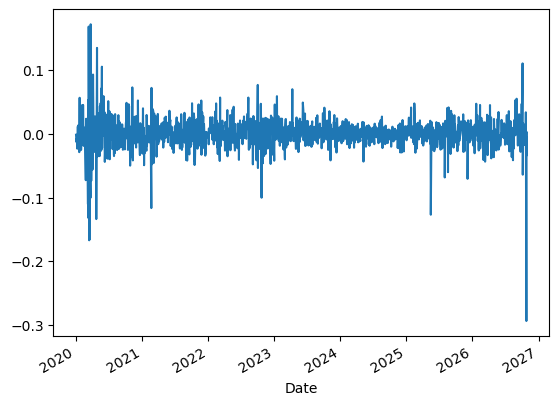

In [28]:
acoes_combined["RS BBRASIL"].plot()

In [29]:
acoes_combined["RS BBRASIL"].mean()

np.float64(0.00027533922709043927)

In [30]:
(acoes_combined["RS BBRASIL"].mean() * 246) * 100

np.float64(6.7733449864248065)

In [31]:
acoes_combined["RS BBRASIL"] =  (acoes_combined["BBRASIL"] / acoes_combined["BBRASIL"].shift(1)) - 1
acoes_combined["RS SANTANDER"] =  (acoes_combined["SANTANDER"] / acoes_combined["SANTANDER"].shift(1)) - 1
acoes_combined["RS BMG"] =  (acoes_combined["BMG"] / acoes_combined["BMG"].shift(1)) - 1
acoes_combined["RS BRADESCO"] =  (acoes_combined["BRADESCO"] / acoes_combined["BRADESCO"].shift(1)) - 1
acoes_combined["RS ITAU"] =  (acoes_combined["ITAU"] / acoes_combined["ITAU"].shift(1)) - 1
acoes_combined["RS BANRISUL"] =  (acoes_combined["BANRISUL"] / acoes_combined["BANRISUL"].shift(1)) - 1
acoes_combined["RS BOVA11"] =  (acoes_combined["BOVA11"] / acoes_combined["BOVA11"].shift(1)) - 1



In [32]:
acoes_combined.head(246)

,BBRASIL,ITAU,SANTANDER,BRADESCO,BMG,BANRISUL,BOVA11,RS BBRASIL,RS SANTANDER,RS BMG,RS BRADESCO,RS ITAU,RS BANRISUL,RS BOVA11
Date,,,,,,,,,,,,,,
2020-01-02,16.931356,22.936810,14.608781,18.192394,5.041269,12.942718,114.239998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,16.903036,22.695555,14.993228,18.201591,4.999213,12.855424,113.800003,-0.001673,0.026316,-0.008342,0.000506,-0.010518,-0.006745,-0.003851
2020-01-06,16.679594,22.357798,14.187619,17.876471,4.883563,12.832145,112.589996,-0.013219,-0.053732,-0.023134,-0.017862,-0.014882,-0.001811,-0.010633
2020-01-07,16.553711,21.839123,13.983168,17.565918,4.888821,12.890341,112.239998,-0.007547,-0.014411,0.001077,-0.017372,-0.023199,0.004535,-0.003109
2020-01-08,16.402645,21.483276,13.791107,17.294170,4.862536,12.610998,111.949997,-0.009126,-0.013735,-0.005376,-0.015470,-0.016294,-0.021671,-0.002584
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-18,12.801075,19.889713,14.049277,14.695519,3.064712,8.377996,113.500000,-0.007362,-0.054390,0.073665,0.001840,-0.001577,0.001440,-0.004299
2020-12-21,12.372189,19.537909,14.386515,14.339202,2.975347,8.155145,111.430000,-0.033504,0.024004,-0.029159,-0.024247,-0.017688,-0.026600,-0.018238
2020-12-22,12.535888,19.632147,14.761928,14.630737,2.985861,8.167191,112.250000,0.013231,0.026095,0.003534,0.020331,0.004823,0.001477,0.007359


In [33]:
acoes_combined

,BBRASIL,ITAU,SANTANDER,BRADESCO,BMG,BANRISUL,BOVA11,RS BBRASIL,RS SANTANDER,RS BMG,RS BRADESCO,RS ITAU,RS BANRISUL,RS BOVA11
Date,,,,,,,,,,,,,,
2020-01-02,16.931356,22.936810,14.608781,18.192394,5.041269,12.942718,114.239998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,16.903036,22.695555,14.993228,18.201591,4.999213,12.855424,113.800003,-0.001673,0.026316,-0.008342,0.000506,-0.010518,-0.006745,-0.003851
2020-01-06,16.679594,22.357798,14.187619,17.876471,4.883563,12.832145,112.589996,-0.013219,-0.053732,-0.023134,-0.017862,-0.014882,-0.001811,-0.010633
2020-01-07,16.553711,21.839123,13.983168,17.565918,4.888821,12.890341,112.239998,-0.007547,-0.014411,0.001077,-0.017372,-0.023199,0.004535,-0.003109
2020-01-08,16.402645,21.483276,13.791107,17.294170,4.862536,12.610998,111.949997,-0.009126,-0.013735,-0.005376,-0.015470,-0.016294,-0.021671,-0.002584
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-23,24.719999,48.299999,13.780000,20.370001,7.210000,18.160000,201.690002,0.033445,-0.003615,0.008392,0.007418,0.006250,0.026569,0.003633
2026-10-26,17.469999,41.700001,13.150000,15.950000,6.160000,14.530000,172.419998,-0.293285,-0.045718,-0.145631,-0.216986,-0.136646,-0.199890,-0.145124
2026-10-27,17.379999,41.189999,13.000000,15.730000,5.710000,13.610000,173.000000,-0.005152,-0.011407,-0.073052,-0.013793,-0.012230,-0.063317,0.003364


In [34]:
(acoes_combined["RS BBRASIL"].mean() * 246) * 100


np.float64(6.7733449864248065)

In [35]:
(acoes_combined["RS SANTANDER"].mean() * 246) * 100

np.float64(2.7363259272893523)

In [36]:
(acoes_combined["RS BMG"].mean() * 246) * 100

np.float64(8.89818114704679)

In [37]:
(acoes_combined["RS BRADESCO"].mean() * 246) * 100

np.float64(3.1975964002459523)

In [38]:
(acoes_combined["RS ITAU"].mean() * 246) * 100

np.float64(12.60304168598299)

In [39]:
(acoes_combined["RS BANRISUL"].mean() * 246) * 100

np.float64(5.9747112970023295)

In [40]:
(acoes_combined["RS BOVA11"].mean() * 246) * 100

np.float64(8.513186919808845)

In [41]:
np.log(acoes_combined["BBRASIL"][len(acoes_combined)- 1] / acoes_combined["BBRASIL"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\645228026.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(-0.659867644310491)

In [42]:
np.log(acoes_combined["BMG"][len(acoes_combined)- 1] / acoes_combined["BMG"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\3291410319.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(6.1306198495405)

In [43]:
np.log(acoes_combined["BRADESCO"][len(acoes_combined)- 1] / acoes_combined["BRADESCO"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\3915590722.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(-23.238747160194322)

In [44]:
np.log(acoes_combined["ITAU"][len(acoes_combined)- 1] / acoes_combined["ITAU"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\672859012.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(55.21284129920001)

In [45]:
np.log(acoes_combined["SANTANDER"][len(acoes_combined)- 1] / acoes_combined["SANTANDER"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\4095107611.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(-18.347091276760832)

In [46]:
np.log(acoes_combined["BANRISUL"][len(acoes_combined)- 1] / acoes_combined["BANRISUL"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\2778875117.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(1.2841992803559685)

In [47]:
np.log(acoes_combined["BOVA11"][len(acoes_combined)- 1] / acoes_combined["BOVA11"][0]) * 100

C:\Users\Pedro\AppData\Local\Temp\ipykernel_1276\1771681396.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



np.float64(38.667388175476354)

In [48]:
acoes_combined["RS BBRASIL"] = np.log(acoes_combined["BBRASIL"] / acoes_combined["BBRASIL"].shift(1))
acoes_combined["RS BMG"] = np.log(acoes_combined["BMG"] / acoes_combined["BMG"].shift(1))
acoes_combined["RS SANTANDER"] = np.log(acoes_combined["SANTANDER"] / acoes_combined["SANTANDER"].shift(1))
acoes_combined["RS ITAU"] = np.log(acoes_combined["ITAU"] / acoes_combined["ITAU"].shift(1))
acoes_combined["RS BRADESCO"] = np.log(acoes_combined["BRADESCO"] / acoes_combined["BRADESCO"].shift(1))
acoes_combined["RS BANRISUL"] = np.log(acoes_combined["BANRISUL"] / acoes_combined["BANRISUL"].shift(1))
acoes_combined["RS BOVA11"] = np.log(acoes_combined["BOVA11"] / acoes_combined["BOVA11"].shift(1))

In [49]:
acoes_combined.head()

,BBRASIL,ITAU,SANTANDER,BRADESCO,BMG,BANRISUL,BOVA11,RS BBRASIL,RS SANTANDER,RS BMG,RS BRADESCO,RS ITAU,RS BANRISUL,RS BOVA11
Date,,,,,,,,,,,,,,
2020-01-02,16.931356,22.936810,14.608781,18.192394,5.041269,12.942718,114.239998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,16.903036,22.695555,14.993228,18.201591,4.999213,12.855424,113.800003,-0.001674,0.025976,-0.008377,0.000505,-0.010574,-0.006767,-0.003859
2020-01-06,16.679594,22.357798,14.187619,17.876471,4.883563,12.832145,112.589996,-0.013307,-0.055229,-0.023405,-0.018024,-0.014994,-0.001812,-0.010690
2020-01-07,16.553711,21.839123,13.983168,17.565918,4.888821,12.890341,112.239998,-0.007576,-0.014515,0.001076,-0.017525,-0.023472,0.004525,-0.003113
2020-01-08,16.402645,21.483276,13.791107,17.294170,4.862536,12.610998,111.949997,-0.009168,-0.013830,-0.005391,-0.015591,-0.016428,-0.021909,-0.002587
